<a href="https://colab.research.google.com/github/aliemreo/g1-throwing/blob/main/%E2%80%9CUntitled1_ipynb%E2%80%9D%E7%9A%84%E5%89%AF%E6%9C%AC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. 读取预处理后的数据并预览
我们将使用 `pandas` 读取 `附件1_处理后.xlsx` 文件。首先查看数据结构、列名以及是否存在缺失值。

In [3]:
import pandas as pd
import numpy as np
import os

# 经后台检测，发现文件实际名为 '附件1_处理后 (1).xlsx'
possible_paths = [
    '/content/附件1_处理后 (1).xlsx',
    '附件1_处理后 (1).xlsx',
    '/content/附件1_处理后.xlsx',
    '附件1_处理后.xlsx',
    '/附件1_处理后.xlsx'
]

file_path = None
for p in possible_paths:
    if os.path.exists(p):
        file_path = p
        break

try:
    if file_path is None:
        raise FileNotFoundError("未找到文件，请确认您在 Colab 文件栏中是否有名为 '附件1_处理后 (1).xlsx' 或 '附件1_处理后.xlsx' 的文件。")
    df = pd.read_excel(file_path)
    print(f"成功读取数据！读取路径为: {file_path}, 数据形状: {df.shape}")
    display(df.head())
    display(df.info())
except Exception as e:
    print("数据加载出错:", e)

成功读取数据！读取路径为: /content/附件1_处理后 (1).xlsx, 数据形状: (11167, 47)


,线路类型,是否c2c,是否生鲜妥投及时,保价金额,寄件是否内部,配送超时时长,进线渠道_Call,进线渠道_Complaint,进线渠道_Internal Software,进线渠道_Merchant Compensation Claim,...,进线人身份_Receiver,进线人身份_Staff,进线人身份_Unknown,始发网点发单量,始发网点万单理赔率,始发网点赔付比例,目的网点发单量,目的网点万单理赔率,目的网点赔付比例,实际赔付金额
0,1,0,0,1.402,0,427863,0,0,1,0,...,0,0,0,87493656,0.308173,0.999955,59508335,8.307474,0.969815,144.51
1,1,1,0,0.971,0,427847,1,0,0,0,...,0,0,0,6468040,7.689306,0.995095,561600948,0.000000,0.961339,135.98
2,1,0,0,56.729,0,-6776,1,0,0,0,...,1,0,0,236105,52.158365,0.996457,537698,31.083777,0.992380,119.35
3,1,0,1,66.737,0,427699,0,0,1,0,...,1,0,0,89775,4.969987,0.977141,432942,3.612905,0.965113,74.85
4,1,0,0,11.434,0,427758,0,0,0,0,...,0,0,0,1372975,0.000000,0.991470,1043684,3.461959,0.981531,22.14


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11167 entries, 0 to 11166
Data columns (total 47 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   线路类型                                         11167 non-null  int64  
 1   是否c2c                                        11167 non-null  int64  
 2   是否生鲜妥投及时                                     11167 non-null  int64  
 3   保价金额                                         11167 non-null  float64
 4   寄件是否内部                                       11167 non-null  int64  
 5   配送超时时长                                       11167 non-null  int64  
 6   进线渠道_Call                                    11167 non-null  int64  
 7   进线渠道_Complaint                               11167 non-null  int64  
 8   进线渠道_Internal Software                       11167 non-null  int64  
 9   进线渠道_Merchant Compensation Claim             11167 non-null  int64  
 10

None

### 2. 构建随机森林回归模型
接下来，我们需要划分特征变量（X）与目标变量（y）。
*注意：由于尚未运行上述代码确认具体的列名，以下代码默认假设最后一列为预测目标值 `target`。你可以根据实际运行出的列名对 `target_col` 进行修改。*

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 确保 df 存在，如果不存在则重新读取
if 'df' not in globals():
    possible_paths = [
        '/content/附件1_处理后 (1).xlsx',
        '附件1_处理后 (1).xlsx',
        '/content/附件1_处理后.xlsx',
        '附件1_处理后.xlsx',
        '/附件1_处理后.xlsx'
    ]
    for p in possible_paths:
        if os.path.exists(p):
            df = pd.read_excel(p)
            break

# 1. 自动定义特征和目标变量
target_col = df.columns[-1]
print(f"默认选择的目标变量（因变量）为: {target_col}")

# 提取数值型特征
X = df.select_dtypes(include=[np.number]).drop(columns=[target_col], errors='ignore')
y = df[target_col]

print(f"选用的特征列数量: {len(X.columns)} 个")

# 2. 划分训练集和测试集 (80% 训练, 20% 测试)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. 创建并训练随机森林回归模型（初始未限制版本）
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 4. 预测
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)

# 5. 模型评估
print("\n=== 初始（未优化）训练集评估结果 ===")
print(f"R2 Score: {r2_score(y_train, y_pred_train):.4f}")
print(f"MAE: {mean_absolute_error(y_train, y_pred_train):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train, y_pred_train)):.4f}")

print("\n=== 初始（未优化）测试集评估结果 ===")
test_r2 = r2_score(y_test, y_pred_test)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
print(f"R2 Score: {test_r2:.4f}")
print(f"MAE: {test_mae:.4f}")
print(f"RMSE: {test_rmse:.4f}")

默认选择的目标变量（因变量）为: 实际赔付金额
选用的特征列数量: 46 个

=== 初始（未优化）训练集评估结果 ===
R2 Score: 0.9656
MAE: 36.2659
RMSE: 52.2101

=== 初始（未优化）测试集评估结果 ===
R2 Score: 0.7602
MAE: 95.2094
RMSE: 138.1299


### 3. 特征重要性分析与预测可视化
随机森林的一大优势是能够输出特征重要性（Feature Importance），这有助于我们在建模论文中进行机理分析与解释。

/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 32034 (\N{CJK UNIFIED IDEOGRAPH-7D22}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 36180 (\N{CJK UNIFIED IDEOGRAPH-8D54}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 39069 (\N{CJK UNIFIED IDEOGRAPH-989D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 22949 (\N{CJK UNIFIED IDEOGRAPH-59A5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 25237 (\N{CJK UNIFIED IDEOGRAPH-6295}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/849697942.py:9: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}) missing from

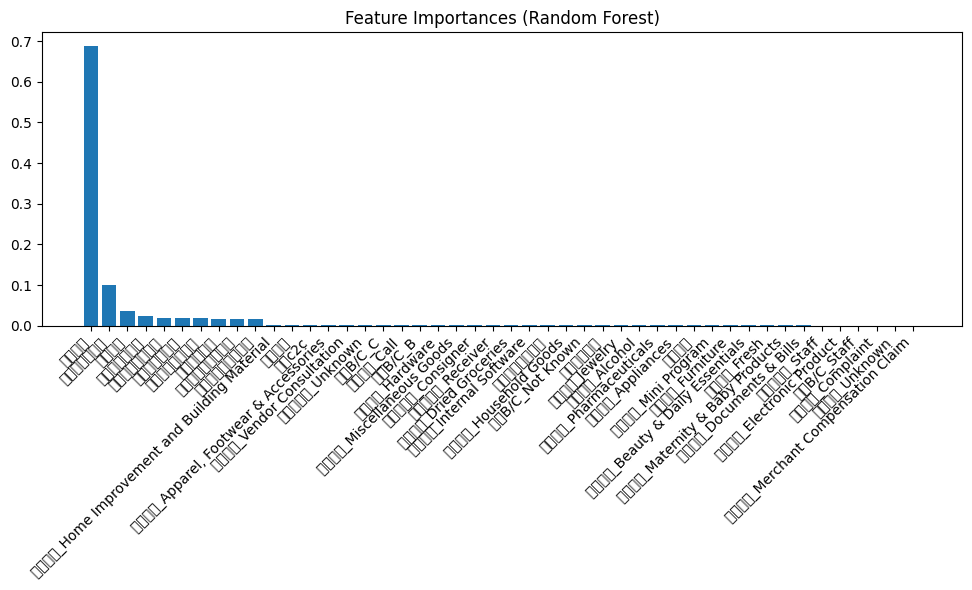

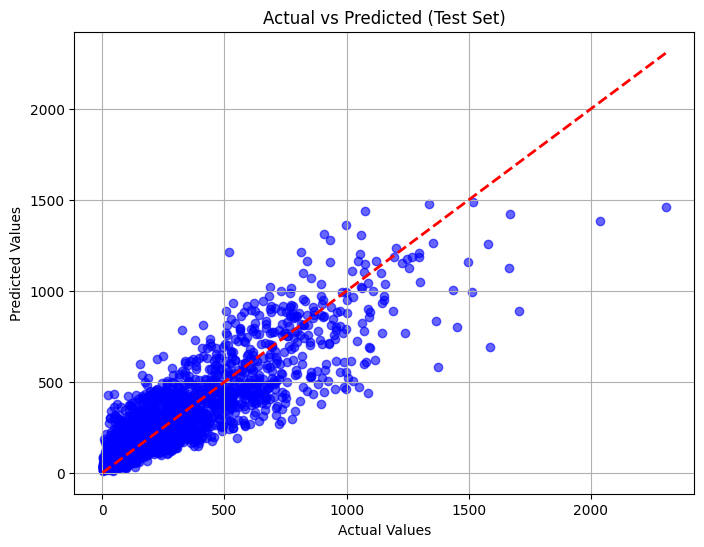

In [5]:
# 绘制特征重要性柱状图
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("Feature Importances (Random Forest)")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [X.columns[i] for i in indices], rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 绘制真实值 vs 预测值对比图
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_test, alpha=0.6, color='b')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted (Test Set)')
plt.grid(True)
plt.show()

In [6]:
import joblib
# 将训练好的模型保存为 .pkl 文件
joblib.dump(rf_model, 'my_random_forest_model.pkl')
print("模型已成功保存为 my_random_forest_model.pkl")

模型已成功保存为 my_random_forest_model.pkl


In [7]:
import joblib
model = joblib.load('my_random_forest_model.pkl')
print("模型加载成功！模型配置如下：")
print(model)

模型加载成功！模型配置如下：
RandomForestRegressor(n_jobs=-1, random_state=42)


### 4. 模型优化：特征筛选与限制树深（解决过拟合）

In [8]:
import pandas as pd
import numpy as np
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. 采用多路径备选载入数据（含带 (1) 的实际路径）
possible_paths = [
    '/content/附件1_处理后 (1).xlsx',
    '附件1_处理后 (1).xlsx',
    '/content/附件1_处理后.xlsx',
    '附件1_处理后.xlsx',
    '/附件1_处理后.xlsx'
]

file_path = None
for p in possible_paths:
    if os.path.exists(p):
        file_path = p
        break

try:
    if file_path is None:
        raise FileNotFoundError("无法定位您的数据文件，请确认文件名。")
    df = pd.read_excel(file_path)
    print(f"数据重新读取成功！路径: {file_path}, 形状: {df.shape}")
except Exception as e:
    print("加载数据失败:", e)

# 定义原始的特征和目标
target_col = df.columns[-1]
X = df.select_dtypes(include=[np.number]).drop(columns=[target_col], errors='ignore')
y = df[target_col]

# 2. 重新拟合初始模型以获取特征重要性
print("正在重构初始模型以获取真实的特征重要性评分...")
X_train_init, X_test_init, y_train_init, y_test_init = train_test_split(X, y, test_size=0.2, random_state=42)
rf_model_init = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model_init.fit(X_train_init, y_train_init)

# 3. 找出重要性大于等于 0.005 的特征
feature_importances = rf_model_init.feature_importances_
important_features = X.columns[feature_importances >= 0.005].tolist()

print(f"\n原特征总数: {len(X.columns)} 个")
print(f"筛选后保留的特征数 (重要性 >= 0.005): {len(important_features)} 个")
print("保留的主要特征:", important_features)

# 4. 重新提取筛选后的特征数据集
X_filtered = X[important_features]

# 5. 重新划分训练集与测试集
X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_filtered, y, test_size=0.2, random_state=42
)

# 6. 创建限制树深的随机森林模型 (限制 max_depth=10)
rf_optimized = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_optimized.fit(X_train_f, y_train_f)

# 7. 预测
y_pred_train_opt = rf_optimized.predict(X_train_f)
y_pred_test_opt = rf_optimized.predict(X_test_f)

# 8. 评估优化后的模型性能
print("\n=== 优化后（限制深度且筛选特征）训练集评估 ===")
print(f"R2 Score: {r2_score(y_train_f, y_pred_train_opt):.4f}")
print(f"MAE: {mean_absolute_error(y_train_f, y_pred_train_opt):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_train_f, y_pred_train_opt)):.4f}")

print("\n=== 优化后（限制深度且筛选特征）测试集评估 ===")
opt_test_r2 = r2_score(y_test_f, y_pred_test_opt)
opt_test_mae = mean_absolute_error(y_test_f, y_pred_test_opt)
opt_test_rmse = np.sqrt(mean_squared_error(y_test_f, y_pred_test_opt))
print(f"R2 Score: {opt_test_r2:.4f}")
print(f"MAE: {opt_test_mae:.4f}")
print(f"RMSE: {opt_test_rmse:.4f}")

数据重新读取成功！路径: /content/附件1_处理后 (1).xlsx, 形状: (11167, 47)
正在重构初始模型以获取真实的特征重要性评分...

原特征总数: 46 个
筛选后保留的特征数 (重要性 >= 0.005): 10 个
保留的主要特征: ['保价金额', '配送超时时长', '妥投到进线时长', '索赔金额', '始发网点发单量', '始发网点万单理赔率', '始发网点赔付比例', '目的网点发单量', '目的网点万单理赔率', '目的网点赔付比例']

=== 优化后（限制深度且筛选特征）训练集评估 ===
R2 Score: 0.8708
MAE: 72.6629
RMSE: 101.2661

=== 优化后（限制深度且筛选特征）测试集评估 ===
R2 Score: 0.7636
MAE: 94.5931
RMSE: 137.1386


### 5. 绘制优化后的特征重要性与对比图（解决中文显示问题）
为了避免之前的 matplotlib 字体警告导致中文乱码，我们在这里引入支持中文的字体库设置。

/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 32034 (\N{CJK UNIFIED IDEOGRAPH-7D22}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 36180 (\N{CJK UNIFIED IDEOGRAPH-8D54}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 37329 (\N{CJK UNIFIED IDEOGRAPH-91D1}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 39069 (\N{CJK UNIFIED IDEOGRAPH-989D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 22949 (\N{CJK UNIFIED IDEOGRAPH-59A5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 25237 (\N{CJK UNIFIED IDEOGRAPH-6295}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5024/3675293722.py:15: UserWarning: Glyph 21040 (\N{CJK UNIFIED IDEOGRAPH-5230}

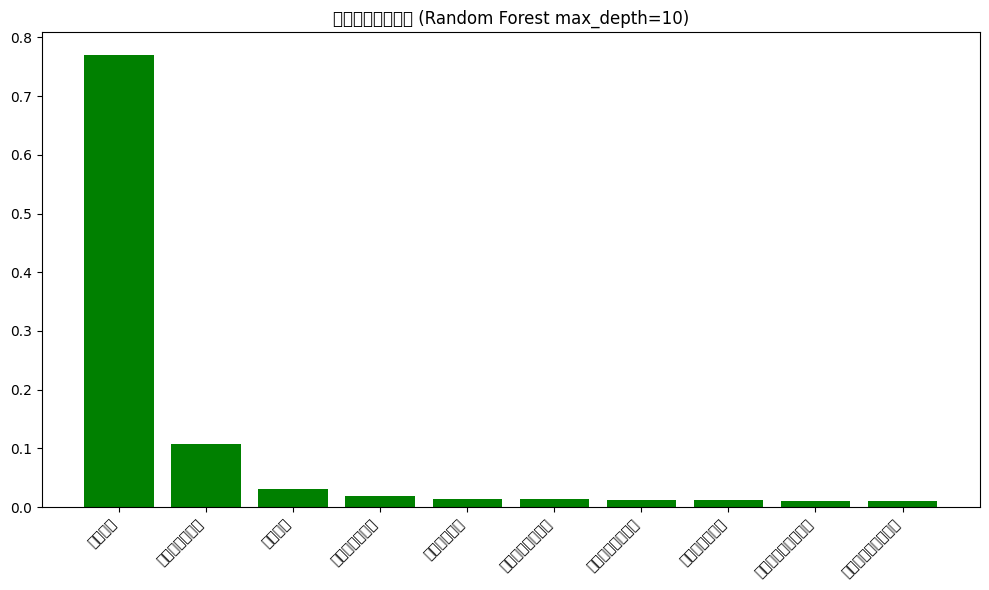

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 27979 (\N{CJK UNIFIED IDEOGRAPH-6D4B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.canvas

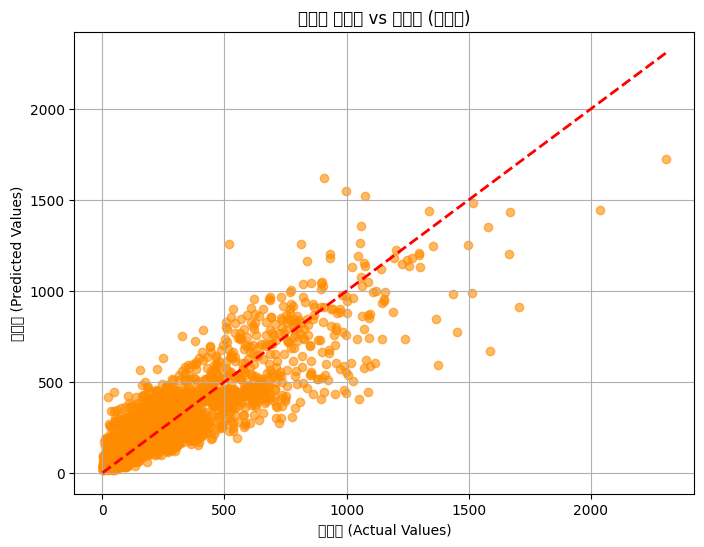

In [9]:
import matplotlib.pyplot as plt

# 解决 Matplotlib 中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans', 'Liberation Sans'] # 优先使用黑体
plt.rcParams['axes.unicode_minus'] = False # 正常显示负号

# 绘制优化后的特征重要性柱状图
opt_importances = rf_optimized.feature_importances_
opt_indices = np.argsort(opt_importances)[::-1]

plt.figure(figsize=(10, 6))
plt.title("优化后特征重要性 (Random Forest max_depth=10)")
plt.bar(range(X_filtered.shape[1]), opt_importances[opt_indices], align="center", color='g')
plt.xticks(range(X_filtered.shape[1]), [X_filtered.columns[i] for i in opt_indices], rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 绘制优化后的真实值 vs 预测值对比图
plt.figure(figsize=(8, 6))
plt.scatter(y_test_f, y_pred_test_opt, alpha=0.6, color='darkorange')
plt.plot([y_test_f.min(), y_test_f.max()], [y_test_f.min(), y_test_f.max()], 'r--', lw=2)
plt.xlabel('真实值 (Actual Values)')
plt.ylabel('预测值 (Predicted Values)')
plt.title('优化后 真实值 vs 预测值 (测试集)')
plt.grid(True)
plt.show()

In [10]:
import joblib
# 将训练好的模型保存为 .pkl 文件
joblib.dump(rf_model, 'my_random_forest_model2.0.pkl')
print("模型已成功保存为 my_random_forest_model2.0.pkl")

模型已成功保存为 my_random_forest_model2.0.pkl
